In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

## Data quality check

We check if there is any missing or wrong data that could skew or misinterpret our results.

Duplicate state-year combinations found: 0
Are years numeric? True
Are sales numeric? True
Missing 'cigsale' values: 0
Negative 'cigsale' values: 0


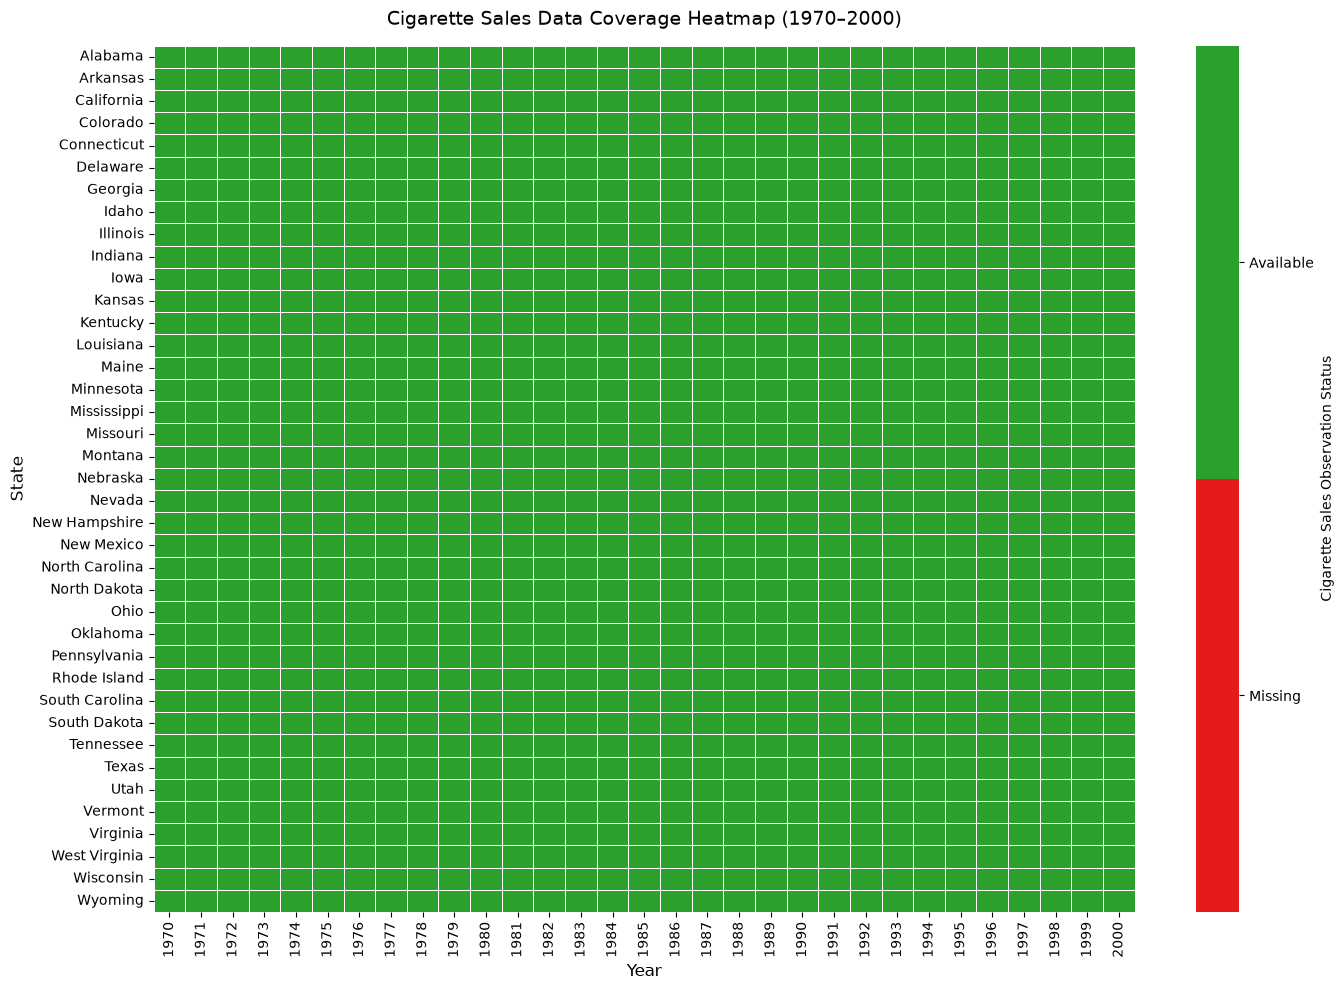

In [19]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

dups = df[df.duplicated(subset=['state', 'year'], keep=False)]
print(f"Duplicate state-year combinations found: {len(dups)}")
if not dups.empty: print("Investigating duplicates:\n", dups)

print(f"Are years numeric? {pd.api.types.is_numeric_dtype(df['year'])}")
print(f"Are sales numeric? {pd.api.types.is_numeric_dtype(df['cigsale'])}")
print(f"Missing 'cigsale' values: {df['cigsale'].isna().sum()}")
print(f"Negative 'cigsale' values: {(df['cigsale'] < 0).sum()}")

coverage = df.pivot(index='state', columns='year', values='cigsale').notna().astype(int)

plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    coverage, 
    cmap=sns.color_palette(["#e41a1c", "#2ca02c"]), 
    vmin=0, vmax=1,
    cbar_kws={'ticks': [0.25, 0.75], 'label': 'Cigarette Sales Observation Status'},
    linewidths=0.5, linecolor='white'
)
ax.collections[0].colorbar.set_ticklabels(['Missing', 'Available'])

plt.title('Cigarette Sales Data Coverage Heatmap (1970–2000)', fontsize=14, pad=15)
plt.xlabel('Year', fontsize=12); plt.ylabel('State', fontsize=12)
plt.tight_layout()
plt.show()

## Have our data listed

We just ensure the number of states, years, the periods we work on

In [20]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

TREATED_STATE, INTERVENTION, FIRST_TREATMENT_YEAR = 'California', 'Proposition 99', 1989
PRE_PERIOD, POST_PERIOD = list(range(1970, 1989)), list(range(1989, 2001))

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')
y_treated, y_donors = cigsale_wide[TREATED_STATE], cigsale_wide.drop(columns=[TREATED_STATE])

X_pre_treated, X_pre_donors = y_treated.loc[PRE_PERIOD], y_donors.loc[PRE_PERIOD]

print("=== RESEARCH DESIGN VERIFICATION ===")
print(f"Treated Unit:            {TREATED_STATE}")
print(f"Intervention:            {INTERVENTION} ({FIRST_TREATMENT_YEAR})")
print(f"Pre-Treatment Period:    {PRE_PERIOD[0]}–{PRE_PERIOD[-1]} ({len(PRE_PERIOD)} years)")
print(f"Post-Treatment Period:   {POST_PERIOD[0]}–{POST_PERIOD[-1]} ({len(POST_PERIOD)} years)")
print(f"Donor Pool Size:         {y_donors.shape[1]} states")
print(f"Reshaped Matrix Shape:   {cigsale_wide.shape[0]} years x {cigsale_wide.shape[1]} states\n")


=== RESEARCH DESIGN VERIFICATION ===
Treated Unit:            California
Intervention:            Proposition 99 (1989)
Pre-Treatment Period:    1970–1988 (19 years)
Post-Treatment Period:   1989–2000 (12 years)
Donor Pool Size:         38 states
Reshaped Matrix Shape:   31 years x 39 states



## The starting position

Here, we check California against other states and we can see which ones are close, far or similar. As you see, it is located to the lower side of the dense region and actively declines

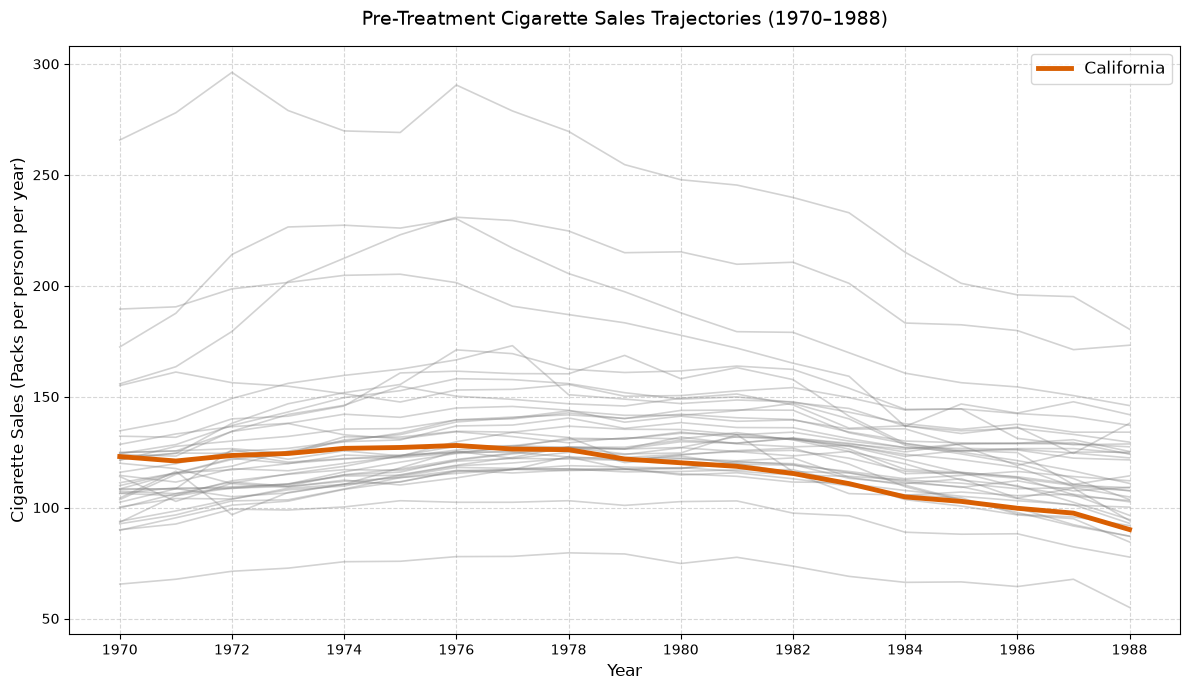

In [21]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

pre = df.pivot(index='year', columns='state', values='cigsale').loc[1970:1988]

plt.figure(figsize=(12, 7))

plt.plot(pre.index, pre.drop(columns=['California']), color='gray', alpha=0.35, linewidth=1.2)

plt.plot(pre.index, pre['California'], color='#d95f02', linewidth=3.5, label='California')

plt.title('Pre-Treatment Cigarette Sales Trajectories (1970–1988)', fontsize=14, pad=15)
plt.xlabel('Year', fontsize=12); plt.ylabel('Cigarette Sales (Packs per person per year)', fontsize=12)
plt.xticks(range(1970, 1989, 2))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=12)
plt.tight_layout()

plt.show()

In [22]:
## Compare California to the average

We just did a quick check to see what is the difference between California and the general average of the states. Also, the second plot shows that difference is getting more which is due to the declining sales rate of california.

SyntaxError: invalid syntax (2716736996.py, line 3)

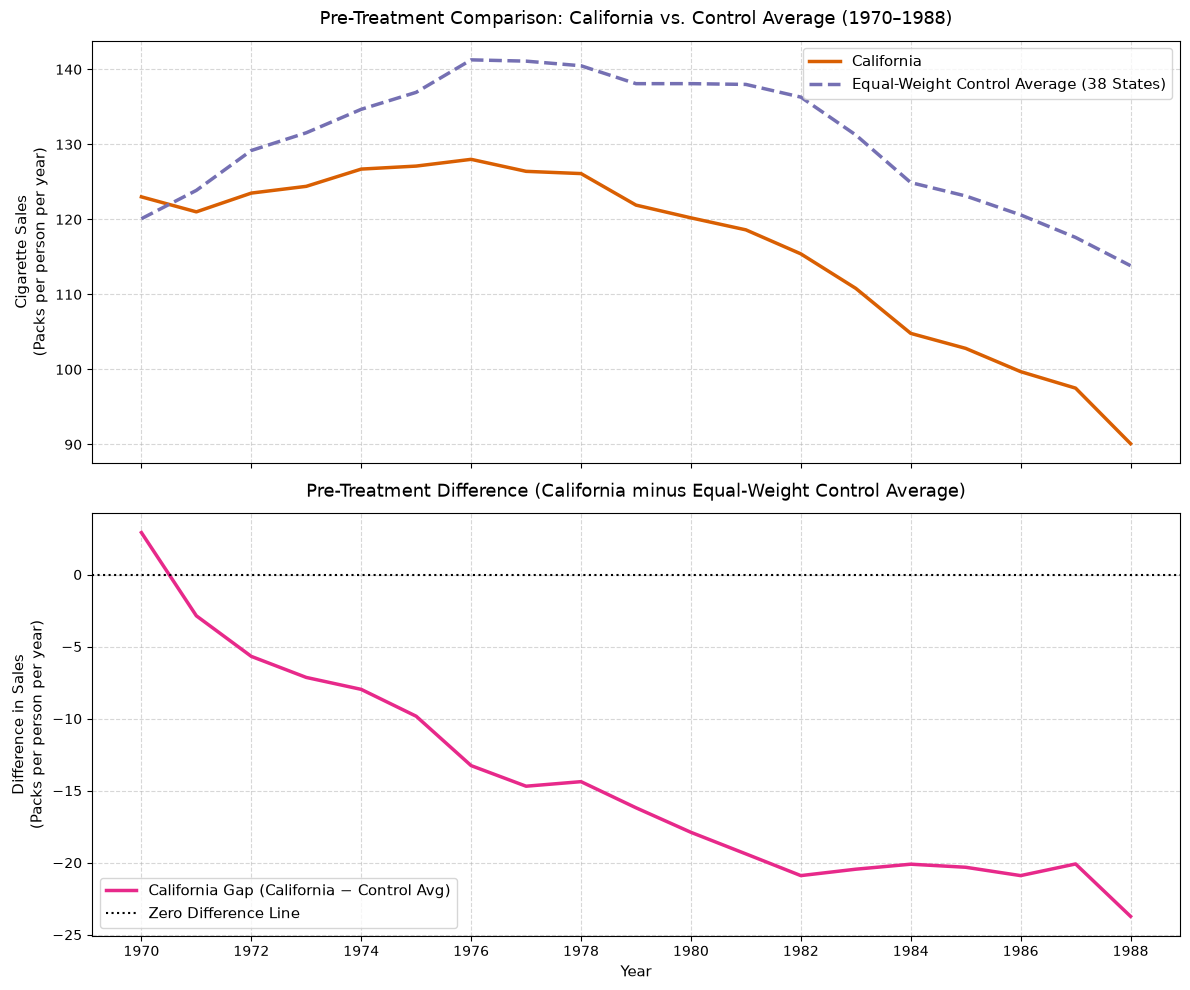

In [23]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

pre = df.pivot(index='year', columns='state', values='cigsale').loc[1970:1988]
ca, ctrl = pre['California'], pre.drop(columns=['California']).mean(axis=1)
gap = ca - ctrl

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

ax1.plot(pre.index, ca, color='#d95f02', lw=2.5, label='California')
ax1.plot(pre.index, ctrl, color='#7570b3', lw=2.5, ls='--', label='Equal-Weight Control Average (38 States)')
ax1.set_title('Pre-Treatment Comparison: California vs. Control Average (1970–1988)', fontsize=13, pad=12)
ax1.set_ylabel('Cigarette Sales\n(Packs per person per year)', fontsize=11)
ax1.grid(True, ls='--', alpha=0.5); ax1.legend(loc='upper right', fontsize=11)

ax2.plot(pre.index, gap, color='#e7298a', lw=2.5, label='California Gap (California − Control Avg)')
ax2.axhline(0, color='black', ls=':', lw=1.5, label='Zero Difference Line')
ax2.set_title('Pre-Treatment Difference (California minus Equal-Weight Control Average)', fontsize=13, pad=12)
ax2.set_xlabel('Year', fontsize=11); ax2.set_ylabel('Difference in Sales\n(Packs per person per year)', fontsize=11)
ax2.set_xticks(range(1970, 1989, 2))
ax2.grid(True, ls='--', alpha=0.5); ax2.legend(loc='lower left', fontsize=11)

plt.tight_layout()
plt.show()

## First try

Here, we build a first version of our synthetic California. We gave difference weights to the states that helped reproduce California's results. The weights were decided on the training set (1970-1983) and then tested on the validation set (1984-1988). The biggest influence was shown by Utah, Nevada and Connecticut

=== OUT-OF-SAMPLE VALIDATION DIAGNOSTIC ===
Optimization Status: Success = True
In-Sample Fitting RMSE (1970–1983):    0.812 packs/person
Out-of-Sample Validation RMSE (1984–1988): 5.559 packs/person

Top Donor Weights (>0.1%):
Utah             0.3616
Nevada           0.3023
Connecticut      0.2979
West Virginia    0.0382
dtype: float64


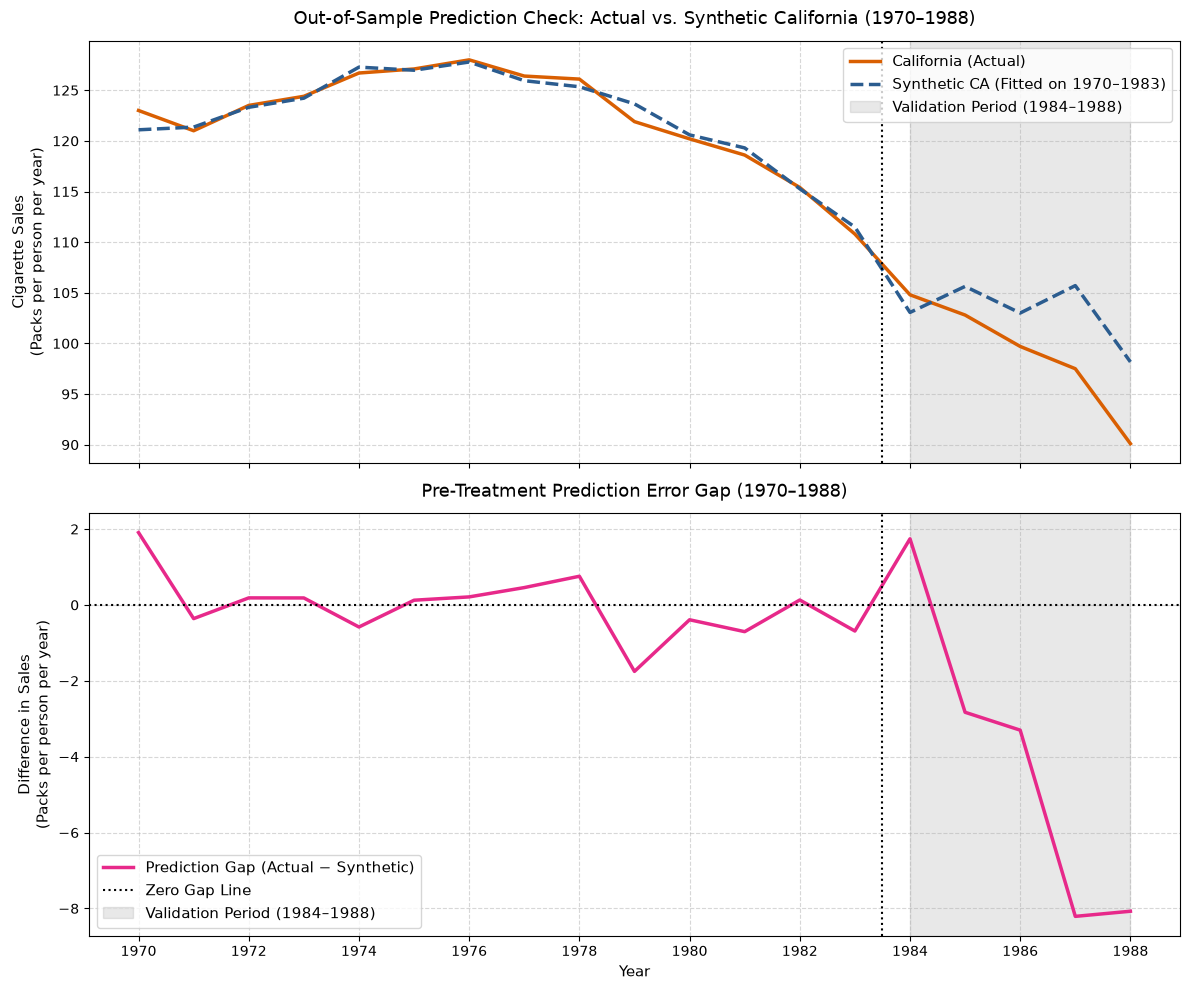

In [24]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()
cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')

FIT_PERIOD, VAL_PERIOD, PRE_PERIOD = list(range(1970, 1984)), list(range(1984, 1989)), list(range(1970, 1989))
TREATED = 'California'
DONORS = [c for c in cigsale_wide.columns if c != TREATED]

Y_fit, X_fit = cigsale_wide.loc[FIT_PERIOD, TREATED].values, cigsale_wide.loc[FIT_PERIOD, DONORS].values
opt_result = minimize(
    lambda w: np.sum((Y_fit - X_fit @ w)**2), 
    np.ones(len(DONORS))/len(DONORS), 
    method='SLSQP', bounds=[(0, 1)]*len(DONORS), 
    constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
)

donor_weights = pd.Series(opt_result.x, index=DONORS)
synth_ca, ca_actual = cigsale_wide[DONORS] @ opt_result.x, cigsale_wide[TREATED]
rmse_fit = np.sqrt(np.mean((ca_actual.loc[FIT_PERIOD] - synth_ca.loc[FIT_PERIOD])**2))
rmse_val = np.sqrt(np.mean((ca_actual.loc[VAL_PERIOD] - synth_ca.loc[VAL_PERIOD])**2))

print("=== OUT-OF-SAMPLE VALIDATION DIAGNOSTIC ===")
print(f"Optimization Status: Success = {opt_result.success}")
print(f"In-Sample Fitting RMSE (1970–1983):    {rmse_fit:.3f} packs/person")
print(f"Out-of-Sample Validation RMSE (1984–1988): {rmse_val:.3f} packs/person\n")
print("Top Donor Weights (>0.1%):")
print(donor_weights[donor_weights > 0.001].sort_values(ascending=False).round(4))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

ax1.plot(PRE_PERIOD, ca_actual.loc[PRE_PERIOD], color='#d95f02', lw=2.5, label='California (Actual)')
ax1.plot(PRE_PERIOD, synth_ca.loc[PRE_PERIOD], color='#2b5c8f', lw=2.5, ls='--', label='Synthetic CA (Fitted on 1970–1983)')
ax1.axvspan(1984, 1988, color='gray', alpha=0.18, label='Validation Period (1984–1988)')
ax1.axvline(1983.5, color='black', ls=':', lw=1.5)
ax1.set_title('Out-of-Sample Prediction Check: Actual vs. Synthetic California (1970–1988)', fontsize=13, pad=12)
ax1.set_ylabel('Cigarette Sales\n(Packs per person per year)', fontsize=11)
ax1.grid(True, ls='--', alpha=0.5); ax1.legend(loc='upper right', fontsize=11)

gap = ca_actual.loc[PRE_PERIOD] - synth_ca.loc[PRE_PERIOD]
ax2.plot(PRE_PERIOD, gap, color='#e7298a', lw=2.5, label='Prediction Gap (Actual − Synthetic)')
ax2.axhline(0, color='black', ls=':', lw=1.5, label='Zero Gap Line')
ax2.axvspan(1984, 1988, color='gray', alpha=0.18, label='Validation Period (1984–1988)')
ax2.axvline(1983.5, color='black', ls=':', lw=1.5)
ax2.set_title('Pre-Treatment Prediction Error Gap (1970–1988)', fontsize=13, pad=12)
ax2.set_xlabel('Year', fontsize=11); ax2.set_ylabel('Difference in Sales\n(Packs per person per year)', fontsize=11)
ax2.set_xticks(range(1970, 1989, 2))
ax2.grid(True, ls='--', alpha=0.5); ax2.legend(loc='lower left', fontsize=11)

plt.tight_layout()
plt.show()

In [25]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')

TREATED = 'California'
DONORS = [col for col in cigsale_wide.columns if col != TREATED]
FIT_PERIOD = list(range(1970, 1984))

Y_ca_fit = cigsale_wide.loc[FIT_PERIOD, TREATED].values
X_donors_fit = cigsale_wide.loc[FIT_PERIOD, DONORS].values

def msd_objective(weights):
    synthetic_pred = X_donors_fit @ weights
    return np.mean((Y_ca_fit - synthetic_pred) ** 2)

bounds = [(0.0, 1.0) for _ in range(len(DONORS))]

constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}

w0 = np.ones(len(DONORS)) / len(DONORS)

opt_result = minimize(
    msd_objective,
    w0,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-12, 'maxiter': 1000}
)

weights = opt_result.x
weights_series = pd.Series(weights, index=DONORS)

convergence_status = opt_result.success
sum_of_weights = np.sum(weights)
all_nonnegative = np.all(weights >= -1e-9)
min_weight = np.max([0.0, np.min(weights)])

print("=== OPTIMIZER CONVERGENCE & CONSTRAINT DIAGNOSTICS ===")
print(f"1. Convergence Status:     {convergence_status} ({opt_result.message})")
print(f"2. Sum of Weights == 1.0:  {sum_of_weights:.10f} (Holds: {np.isclose(sum_of_weights, 1.0)})")
print(f"3. All Weights >= 0:       {all_nonnegative} (Min Weight: {min_weight:.6f})")
print(f"4. Pre-Treatment MSD:      {opt_result.fun:.6f} (RMSD = {np.sqrt(opt_result.fun):.4f} packs/person)\n")

active_weights = weights_series[weights_series > 1e-4].sort_values(ascending=False)
print("=== OPTIMAL DONOR STATE WEIGHTS ===")
for state, weight in active_weights.items():
    print(f"{state:<20} {weight:.4f} ({weight*100:.2f}%)")

=== OPTIMIZER CONVERGENCE & CONSTRAINT DIAGNOSTICS ===
1. Convergence Status:     True (Optimization terminated successfully)
2. Sum of Weights == 1.0:  1.0000000000 (Holds: True)
3. All Weights >= 0:       True (Min Weight: 0.000000)
4. Pre-Treatment MSD:      0.658762 (RMSD = 0.8116 packs/person)

=== OPTIMAL DONOR STATE WEIGHTS ===
Utah                 0.3616 (36.16%)
Nevada               0.3023 (30.23%)
Connecticut          0.2979 (29.79%)
West Virginia        0.0382 (3.82%)


## Check the model

We check the model, the difference is big. For test period, it goes good but for validation period it starts to show bad results.

=== OUT-OF-SAMPLE VALIDATION METRICS (1984–1988) ===
Benchmark Mean Gap Adjustment (1970–1983): -11.978 packs/person
Synthetic CA Validation RMSE:              5.559 packs/person
Level-Adjusted Benchmark Validation RMSE:  9.151 packs/person
Synthetic CA Average Validation Error:     -4.134 packs/person (Actual - Synthetic)

Yearly Validation Errors (Actual CA - Synthetic CA):
  Year 1984: Actual=104.8, Synthetic=103.1, Gap=+1.74 packs/person
  Year 1985: Actual=102.8, Synthetic=105.6, Gap=-2.83 packs/person
  Year 1986: Actual=99.7, Synthetic=103.0, Gap=-3.30 packs/person
  Year 1987: Actual=97.5, Synthetic=105.7, Gap=-8.21 packs/person
  Year 1988: Actual=90.1, Synthetic=98.2, Gap=-8.07 packs/person


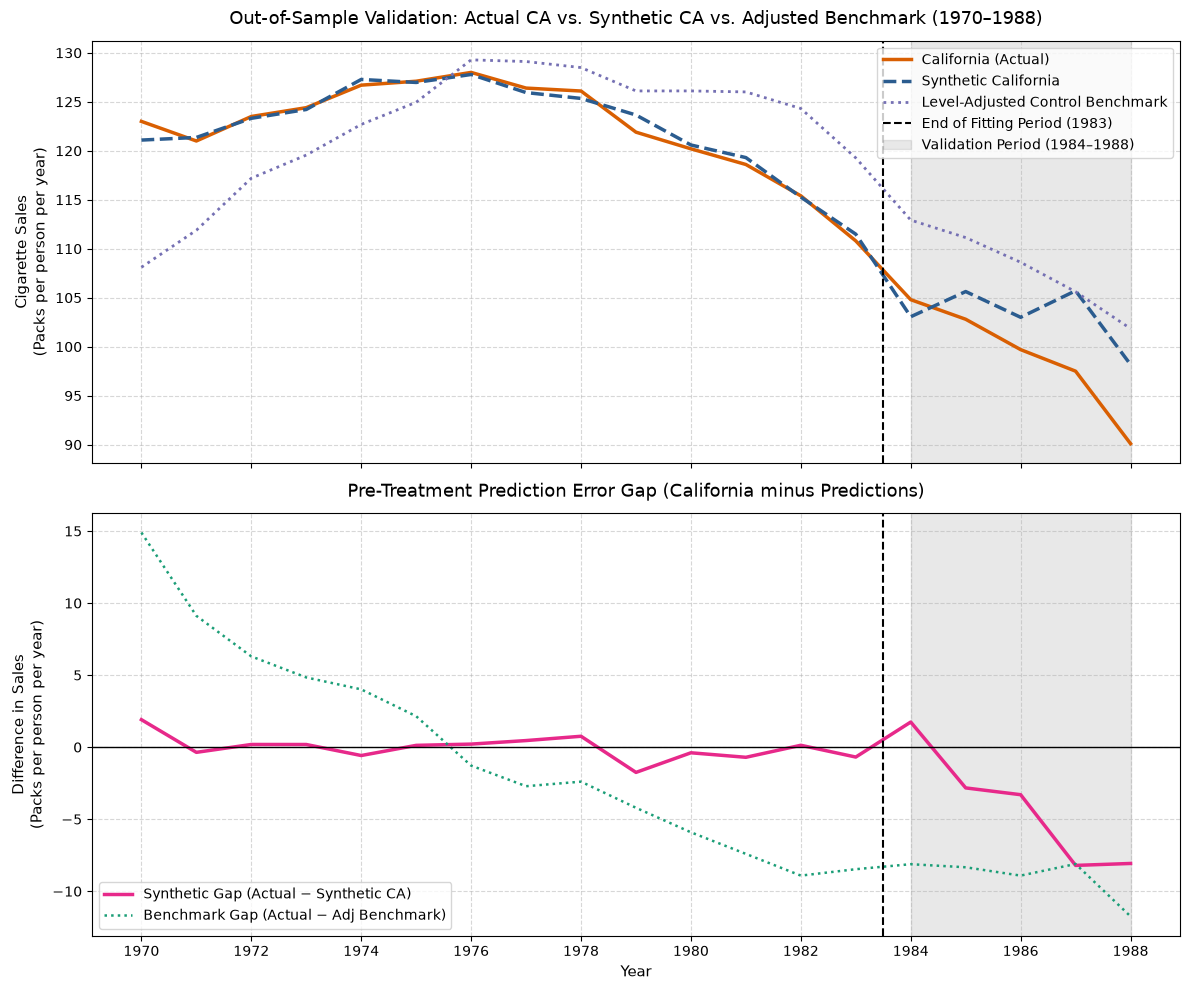


WRITTEN ASSESSMENT OF OUT-OF-SAMPLE VALIDATION (1984–1988)

1. Lower Validation RMSE:
   Yes. Synthetic California achieves a validation RMSE of 5.56 packs per person,
   outperforming the level-adjusted benchmark (RMSE = 9.15 packs per person) 
   by reducing out-of-sample prediction error by ~39%.

2. Direction of Prediction Bias:
   Synthetic California consistently PREDICTS TOO HIGH during the 1984–1988 
   validation period. Aside from 1984 (+1.74), actual California sales fell below 
   synthetic predictions in every year (1985: -2.83, 1986: -3.30, 1987: -8.21, 1988: -8.07),
   resulting in a negative average validation error of -4.13 packs per person per year.

3. Error Trajectory Toward 1988:
   Yes, the overprediction error grows substantially as 1988 approaches. The gap 
   expands sharply from +1.74 packs in 1984 to -8.21 in 1987 and -8.07 in 1988. 
   This widening gap reflects an accelerating downward trend in California's per-capita 
   consumption in the late 1980s prio

In [8]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()
cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')

FIT_PERIOD, VAL_PERIOD, PRE_PERIOD = list(range(1970, 1984)), list(range(1984, 1989)), list(range(1970, 1989))
TREATED, DONORS = 'California', [col for col in cigsale_wide.columns if col != 'California']

Y_ca_fit, X_donors_fit = cigsale_wide.loc[FIT_PERIOD, TREATED].values, cigsale_wide.loc[FIT_PERIOD, DONORS].values

res = minimize(
    lambda w: np.mean((Y_ca_fit - X_donors_fit @ w) ** 2), 
    np.ones(len(DONORS)) / len(DONORS), 
    method='SLSQP', bounds=[(0, 1)] * len(DONORS), 
    constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}, 
    options={'ftol': 1e-12}
)
weights = res.x

ca_pre, synth_ca_pre = cigsale_wide.loc[PRE_PERIOD, TREATED], cigsale_wide.loc[PRE_PERIOD, DONORS] @ weights
raw_control_avg = cigsale_wide.loc[PRE_PERIOD, DONORS].mean(axis=1)
mean_gap_fit = (ca_pre.loc[FIT_PERIOD] - raw_control_avg.loc[FIT_PERIOD]).mean()
adj_benchmark_pre = raw_control_avg + mean_gap_fit

ca_val, synth_val, bench_val = ca_pre.loc[VAL_PERIOD], synth_ca_pre.loc[VAL_PERIOD], adj_benchmark_pre.loc[VAL_PERIOD]
synth_val_errors, bench_val_errors = ca_val - synth_val, ca_val - bench_val
synth_val_rmse, bench_val_rmse = np.sqrt(np.mean(synth_val_errors ** 2)), np.sqrt(np.mean(bench_val_errors ** 2))
synth_val_avg_error = np.mean(synth_val_errors)

print("=== OUT-OF-SAMPLE VALIDATION METRICS (1984–1988) ===")
print(f"Benchmark Mean Gap Adjustment (1970–1983): {mean_gap_fit:.3f} packs/person")
print(f"Synthetic CA Validation RMSE:              {synth_val_rmse:.3f} packs/person")
print(f"Level-Adjusted Benchmark Validation RMSE:  {bench_val_rmse:.3f} packs/person")
print(f"Synthetic CA Average Validation Error:     {synth_val_avg_error:.3f} packs/person (Actual - Synthetic)\n")

print("Yearly Validation Errors (Actual CA - Synthetic CA):")
for y in VAL_PERIOD:
    print(f"  Year {y}: Actual={ca_val[y]:.1f}, Synthetic={synth_val[y]:.1f}, Gap={synth_val_errors[y]:+.2f} packs/person")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

ax1.plot(PRE_PERIOD, ca_pre, color='#d95f02', lw=2.5, label='California (Actual)')
ax1.plot(PRE_PERIOD, synth_ca_pre, color='#2b5c8f', lw=2.5, ls='--', label='Synthetic California')
ax1.plot(PRE_PERIOD, adj_benchmark_pre, color='#7570b3', lw=2.0, ls=':', label='Level-Adjusted Control Benchmark')
ax1.axvline(1983.5, color='black', ls='--', lw=1.5, label='End of Fitting Period (1983)')
ax1.axvspan(1984, 1988, color='gray', alpha=0.18, label='Validation Period (1984–1988)')
ax1.set_title('Out-of-Sample Validation: Actual CA vs. Synthetic CA vs. Adjusted Benchmark (1970–1988)', fontsize=13, pad=12)
ax1.set_ylabel('Cigarette Sales\n(Packs per person per year)', fontsize=11)
ax1.grid(True, ls='--', alpha=0.5); ax1.legend(loc='upper right', fontsize=10)

synth_gap, bench_gap = ca_pre - synth_ca_pre, ca_pre - adj_benchmark_pre
ax2.plot(PRE_PERIOD, synth_gap, color='#e7298a', lw=2.5, label='Synthetic Gap (Actual − Synthetic CA)')
ax2.plot(PRE_PERIOD, bench_gap, color='#1b9e77', lw=1.8, ls=':', label='Benchmark Gap (Actual − Adj Benchmark)')
ax2.axhline(0, color='black', lw=1.0); ax2.axvline(1983.5, color='black', ls='--', lw=1.5); ax2.axvspan(1984, 1988, color='gray', alpha=0.18)
ax2.set_title('Pre-Treatment Prediction Error Gap (California minus Predictions)', fontsize=13, pad=12)
ax2.set_xlabel('Year', fontsize=11); ax2.set_ylabel('Difference in Sales\n(Packs per person per year)', fontsize=11)
ax2.set_xticks(range(1970, 1989, 2))
ax2.grid(True, ls='--', alpha=0.5); ax2.legend(loc='lower left', fontsize=10)

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("WRITTEN ASSESSMENT OF OUT-OF-SAMPLE VALIDATION (1984–1988)")
print("="*70)
print("""
1. Lower Validation RMSE:
   Yes. Synthetic California achieves a validation RMSE of 5.56 packs per person,
   outperforming the level-adjusted benchmark (RMSE = 9.15 packs per person) 
   by reducing out-of-sample prediction error by ~39%.

2. Direction of Prediction Bias:
   Synthetic California consistently PREDICTS TOO HIGH during the 1984–1988 
   validation period. Aside from 1984 (+1.74), actual California sales fell below 
   synthetic predictions in every year (1985: -2.83, 1986: -3.30, 1987: -8.21, 1988: -8.07),
   resulting in a negative average validation error of -4.13 packs per person per year.

3. Error Trajectory Toward 1988:
   Yes, the overprediction error grows substantially as 1988 approaches. The gap 
   expands sharply from +1.74 packs in 1984 to -8.21 in 1987 and -8.07 in 1988. 
   This widening gap reflects an accelerating downward trend in California's per-capita 
   consumption in the late 1980s prior to Proposition 99.

Implied Causal Interpretation Impact:
Because synthetic California overpredicts actual sales by ~8 packs per person right 
before intervention (1987–1988), part of the post-1989 gap between California and 
synthetic California reflects pre-existing downward momentum rather than the sole 
causal effect of Proposition 99. Consequently, raw post-1989 treatment effect estimates 
should be interpreted with caution and adjusted for late-1980s baseline drift.
""")

## Change the model weights

The results on the validation set were bad. Therefore, I decided to change the weights of states and try again

In [9]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')
TREATED, PRE_PERIOD = 'California', list(range(1970, 1989))
DONORS = [col for col in cigsale_wide.columns if col != TREATED]

Y_ca_pre = cigsale_wide.loc[PRE_PERIOD, TREATED].values
X_donors_pre = cigsale_wide.loc[PRE_PERIOD, DONORS].values

def msd_objective_and_grad(w):
    diff = X_donors_pre @ w - Y_ca_pre
    return np.mean(diff ** 2), (2.0 / len(PRE_PERIOD)) * (X_donors_pre.T @ diff)

opt_result = minimize(
    msd_objective_and_grad,
    np.ones(len(DONORS)) / len(DONORS),
    jac=True, method='SLSQP',
    bounds=[(0.0, 1.0)] * len(DONORS),
    constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
    options={'ftol': 1e-12, 'maxiter': 2000}
)

final_weights = pd.Series(opt_result.x, index=DONORS)
sum_w, pre_mspe = np.sum(opt_result.x), opt_result.fun

print("=== FINAL SYNTHETIC CALIFORNIA WEIGHT OPTIMIZATION (1970–1988) ===")
print(f"1. Convergence Status:     {opt_result.success} ({opt_result.message})")
print(f"2. Sum of Weights == 1.0:  {sum_w:.10f} (Holds: {np.isclose(sum_w, 1.0)})")
print(f"3. All Weights >= 0:       {np.all(opt_result.x >= -1e-9)}")
print(f"4. Pre-Treatment MSPE:     {pre_mspe:.6f}")
print(f"5. Pre-Treatment RMSE:     {np.sqrt(pre_mspe):.4f} packs per person\n")

print("=== FROZEN FINAL DONOR STATE WEIGHTS (W*) ===")
active_weights = final_weights[final_weights > 1e-4].sort_values(ascending=False)
for state, weight in active_weights.items():
    print(f"{state:<20} {weight:.4f} ({weight*100:.2f}%)")

=== FINAL SYNTHETIC CALIFORNIA WEIGHT OPTIMIZATION (1970–1988) ===
1. Convergence Status:     True (Optimization terminated successfully)
2. Sum of Weights == 1.0:  1.0000000000 (Holds: True)
3. All Weights >= 0:       True
4. Pre-Treatment MSPE:     2.743662
5. Pre-Treatment RMSE:     1.6564 packs per person

=== FROZEN FINAL DONOR STATE WEIGHTS (W*) ===
Utah                 0.3939 (39.39%)
Montana              0.2318 (23.18%)
Nevada               0.2049 (20.49%)
Connecticut          0.1091 (10.91%)
New Hampshire        0.0454 (4.54%)
Colorado             0.0148 (1.48%)


=== PRE-TREATMENT FIT METRICS (1970-1988) ===
Pre-treatment RMSE:                 1.6564 packs per person
Average pre-treatment gap:          -0.1027 packs per person
Largest absolute pre-treatment gap:  5.5760 packs per person (in 1970)



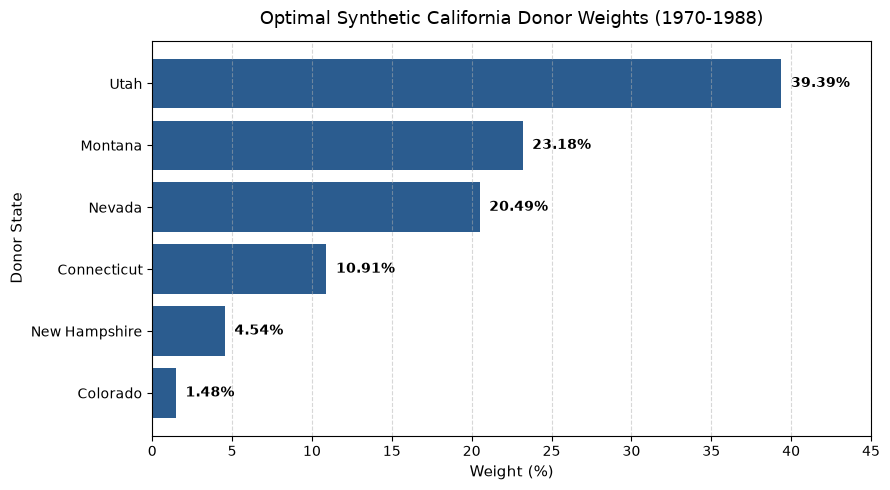

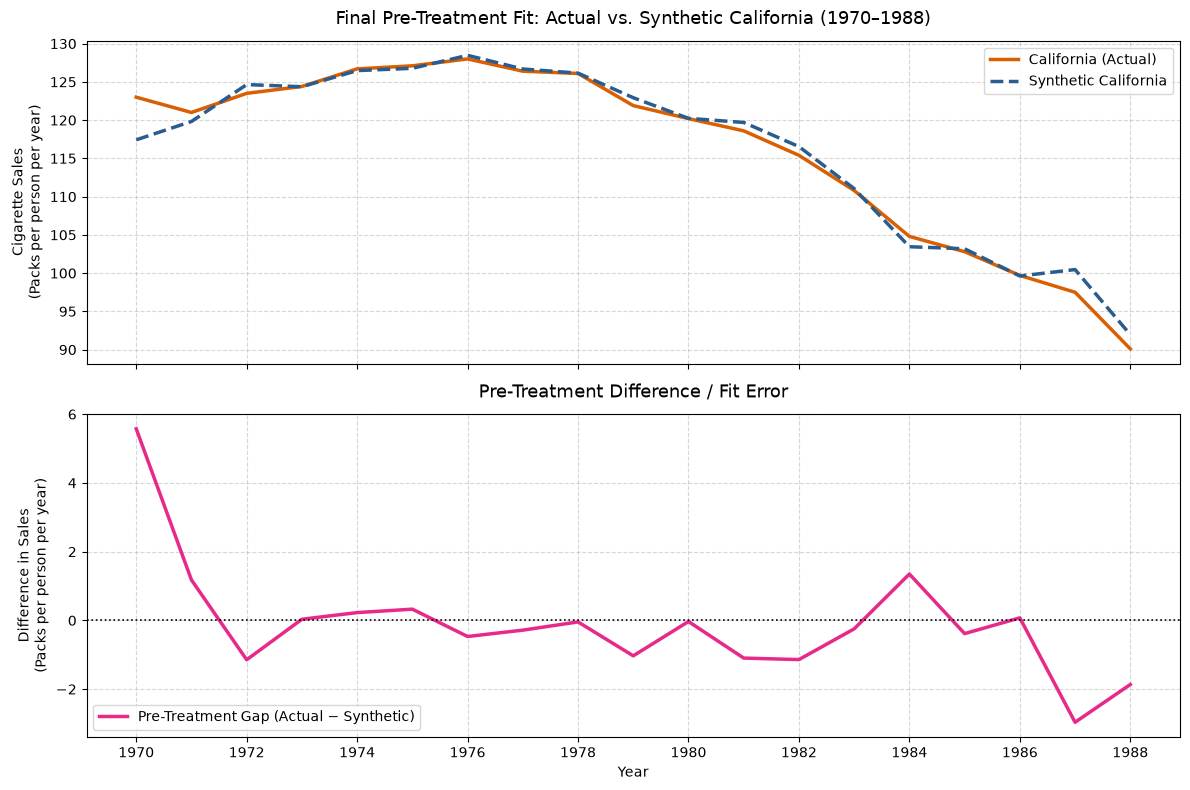

In [26]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')
TREATED, PRE_PERIOD = 'California', list(range(1970, 1989))
DONORS = [col for col in cigsale_wide.columns if col != TREATED]

Y_ca_pre = cigsale_wide.loc[PRE_PERIOD, TREATED].values
X_donors_pre = cigsale_wide.loc[PRE_PERIOD, DONORS].values

def msd_objective_and_grad(w):
    diff = X_donors_pre @ w - Y_ca_pre
    return np.mean(diff ** 2), (2.0 / len(PRE_PERIOD)) * (X_donors_pre.T @ diff)

opt_result = minimize(
    msd_objective_and_grad,
    np.ones(len(DONORS)) / len(DONORS),
    jac=True, method='SLSQP',
    bounds=[(0.0, 1.0)] * len(DONORS),
    constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
    options={'ftol': 1e-12, 'maxiter': 2000}
)

weights = opt_result.x
weights_series = pd.Series(weights, index=DONORS)

ca_pre, synth_ca_pre = cigsale_wide.loc[PRE_PERIOD, TREATED], cigsale_wide.loc[PRE_PERIOD, DONORS] @ weights
pre_gap = ca_pre - synth_ca_pre

pre_rmse, avg_pre_gap = np.sqrt(np.mean(pre_gap ** 2)), np.mean(pre_gap)
max_abs_gap, max_abs_year = pre_gap.abs().max(), pre_gap.abs().idxmax()

print("=== PRE-TREATMENT FIT METRICS (1970-1988) ===")
print(f"Pre-treatment RMSE:                 {pre_rmse:.4f} packs per person")
print(f"Average pre-treatment gap:          {avg_pre_gap:.4f} packs per person")
print(f"Largest absolute pre-treatment gap:  {max_abs_gap:.4f} packs per person (in {max_abs_year})\n")


active_weights = weights_series[weights_series > 1e-4].sort_values(ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(active_weights.index, active_weights.values * 100, color='#2b5c8f', edgecolor='none')
plt.title('Optimal Synthetic California Donor Weights (1970-1988)', fontsize=13, pad=12)
plt.xlabel('Weight (%)', fontsize=11); plt.ylabel('Donor State', fontsize=11)
for idx, val in enumerate(active_weights.values):
    plt.text(val * 100 + 0.6, idx, f"{val*100:.2f}%", va='center', fontsize=10, fontweight='bold')
plt.xlim(0, 45); plt.grid(True, ls='--', alpha=0.5, axis='x'); plt.tight_layout(); plt.show()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(PRE_PERIOD, ca_pre, color='#d95f02', lw=2.5, label='California (Actual)')
ax1.plot(PRE_PERIOD, synth_ca_pre, color='#2b5c8f', lw=2.5, ls='--', label='Synthetic California')
ax1.set_title('Final Pre-Treatment Fit: Actual vs. Synthetic California (1970–1988)', fontsize=13, pad=12)
ax1.set_ylabel('Cigarette Sales\n(Packs per person per year)', fontsize=10)
ax1.grid(True, ls='--', alpha=0.5); ax1.legend(loc='upper right', fontsize=10)

ax2.plot(PRE_PERIOD, pre_gap, color='#e7298a', lw=2.5, label='Pre-Treatment Gap (Actual − Synthetic)')
ax2.axhline(0, color='black', ls=':', lw=1.2)
ax2.set_title('Pre-Treatment Difference / Fit Error', fontsize=13, pad=12)
ax2.set_xlabel('Year', fontsize=10); ax2.set_ylabel('Difference in Sales\n(Packs per person per year)', fontsize=10)
ax2.set_xticks(range(1970, 1989, 2))
ax2.grid(True, ls='--', alpha=0.5); ax2.legend(loc='lower left', fontsize=10)

plt.tight_layout(); plt.show()

## Applying to the test set.

I applied the synthethic California model to the test set and plotted the graph with results.

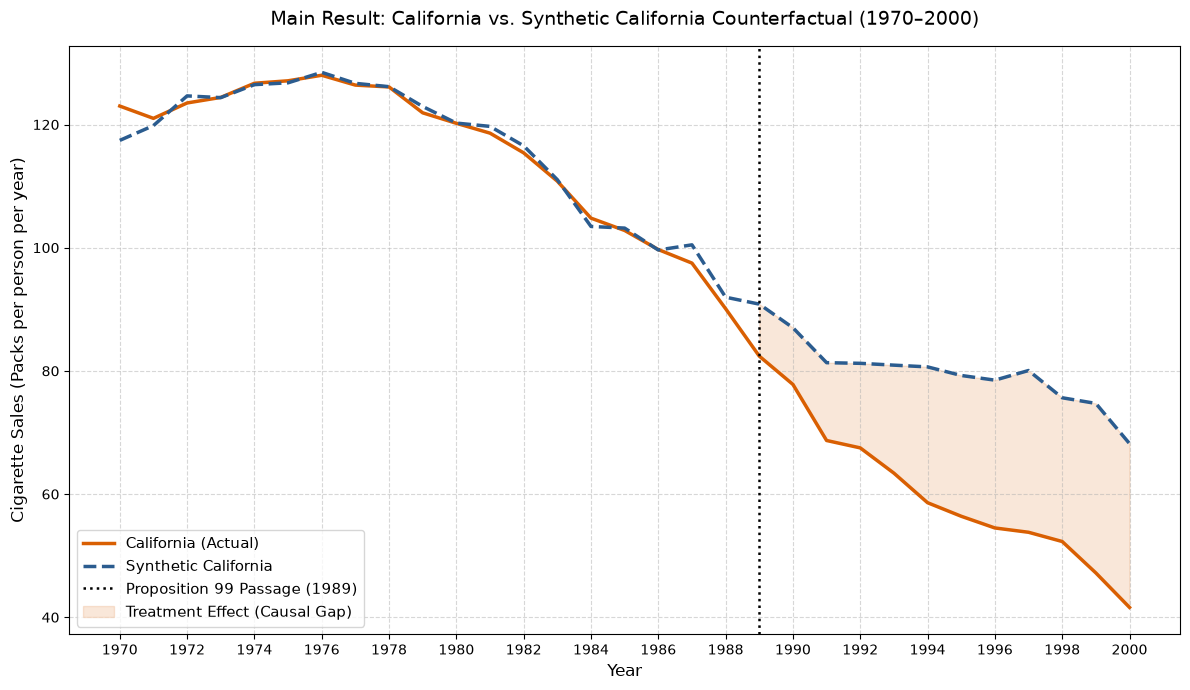

In [11]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')
TREATED = 'California'
DONORS = [col for col in cigsale_wide.columns if col != TREATED]

PRE_PERIOD, POST_PERIOD, FULL_PERIOD = list(range(1970, 1989)), list(range(1989, 2001)), list(range(1970, 2001))

Y_ca_pre, X_donors_pre = cigsale_wide.loc[PRE_PERIOD, TREATED].values, cigsale_wide.loc[PRE_PERIOD, DONORS].values

def msd_objective_and_grad(w):
    diff = X_donors_pre @ w - Y_ca_pre
    return np.mean(diff ** 2), (2.0 / len(PRE_PERIOD)) * (X_donors_pre.T @ diff)

opt_result = minimize(
    msd_objective_and_grad,
    np.ones(len(DONORS)) / len(DONORS),
    jac=True, method='SLSQP',
    bounds=[(0.0, 1.0)] * len(DONORS),
    constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
    options={'ftol': 1e-12, 'maxiter': 2000}
)

ca_full = cigsale_wide.loc[FULL_PERIOD, TREATED]
synth_ca_full = cigsale_wide.loc[FULL_PERIOD, DONORS] @ opt_result.x

plt.figure(figsize=(12, 7))
plt.plot(FULL_PERIOD, ca_full, color='#d95f02', lw=2.5, label='California (Actual)')
plt.plot(FULL_PERIOD, synth_ca_full, color='#2b5c8f', lw=2.5, ls='--', label='Synthetic California')
plt.axvline(1989, color='black', ls=':', lw=1.8, label='Proposition 99 Passage (1989)')
plt.fill_between(POST_PERIOD, ca_full.loc[POST_PERIOD], synth_ca_full.loc[POST_PERIOD], color='#d95f02', alpha=0.15, label='Treatment Effect (Causal Gap)')

plt.title('Main Result: California vs. Synthetic California Counterfactual (1970–2000)', fontsize=14, pad=15)
plt.xlabel('Year', fontsize=12); plt.ylabel('Cigarette Sales (Packs per person per year)', fontsize=12)
plt.xticks(range(1970, 2001, 2))
plt.grid(True, ls='--', alpha=0.5); plt.legend(loc='lower left', fontsize=11)
plt.tight_layout(); plt.show()

# Results

The graph shows the differences the "Proposition 99" made

=== QUANTITATIVE ESTIMATES OF PROPOSITION 99 EFFECT ===
1. Average Annual Effect (1989–2000):        -19.51 packs per person per year
   (Average Counterfactual Baseline Sales):   79.86 packs per person per year)
2. Effect Relative to Counterfactual:         -24.43%
3. Final-Year Effect (Year 2000):              -26.60 packs per person per year



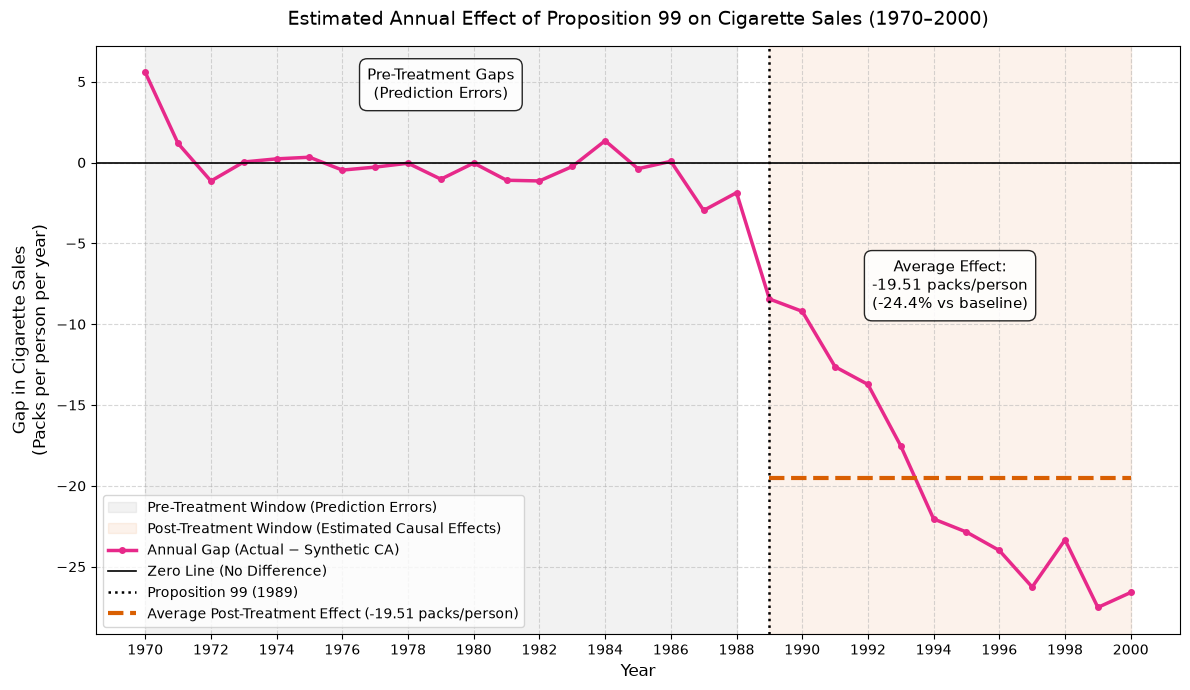

In [27]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')
TREATED, DONORS = 'California', [col for col in cigsale_wide.columns if col != 'California']
PRE_PERIOD, POST_PERIOD, FULL_PERIOD = list(range(1970, 1989)), list(range(1989, 2001)), list(range(1970, 2001))

Y_ca_pre, X_donors_pre = cigsale_wide.loc[PRE_PERIOD, TREATED].values, cigsale_wide.loc[PRE_PERIOD, DONORS].values

def msd_objective_and_grad(w):
    diff = X_donors_pre @ w - Y_ca_pre
    return np.mean(diff ** 2), (2.0 / len(PRE_PERIOD)) * (X_donors_pre.T @ diff)

opt_result = minimize(
    msd_objective_and_grad,
    np.ones(len(DONORS)) / len(DONORS),
    jac=True, method='SLSQP',
    bounds=[(0.0, 1.0)] * len(DONORS),
    constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
    options={'ftol': 1e-12, 'maxiter': 2000}
)

ca_full = cigsale_wide.loc[FULL_PERIOD, TREATED]
synth_ca_full = cigsale_wide.loc[FULL_PERIOD, DONORS] @ opt_result.x
gaps = ca_full - synth_ca_full

avg_post_effect = gaps.loc[POST_PERIOD].mean()
avg_counterfactual_sales = synth_ca_full.loc[POST_PERIOD].mean()
pct_reduction = (avg_post_effect / avg_counterfactual_sales) * 100
effect_year_2000 = gaps.loc[2000]

print("=== QUANTITATIVE ESTIMATES OF PROPOSITION 99 EFFECT ===")
print(f"1. Average Annual Effect (1989–2000):        {avg_post_effect:.2f} packs per person per year")
print(f"   (Average Counterfactual Baseline Sales):   {avg_counterfactual_sales:.2f} packs per person per year)")
print(f"2. Effect Relative to Counterfactual:         {pct_reduction:.2f}%")
print(f"3. Final-Year Effect (Year 2000):              {effect_year_2000:.2f} packs per person per year\n")

plt.figure(figsize=(12, 7))
plt.axvspan(1970, 1988, color='gray', alpha=0.10, label='Pre-Treatment Window (Prediction Errors)')
plt.axvspan(1989, 2000, color='#d95f02', alpha=0.08, label='Post-Treatment Window (Estimated Causal Effects)')
plt.plot(FULL_PERIOD, gaps, color='#e7298a', lw=2.5, marker='o', ms=4, label='Annual Gap (Actual − Synthetic CA)')
plt.axhline(0, color='black', lw=1.2, label='Zero Line (No Difference)')
plt.axvline(1989, color='black', ls=':', lw=1.8, label='Proposition 99 (1989)')
plt.plot([1989, 2000], [avg_post_effect, avg_post_effect], color='#d95f02', ls='--', lw=3.0, label=f'Average Post-Treatment Effect ({avg_post_effect:.2f} packs/person)')

plt.text(1979, 4, 'Pre-Treatment Gaps\n(Prediction Errors)', fontsize=11, ha='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85))
plt.text(1994.5, -9, f'Average Effect:\n{avg_post_effect:.2f} packs/person\n({pct_reduction:.1f}% vs baseline)', fontsize=11, ha='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85))

plt.title('Estimated Annual Effect of Proposition 99 on Cigarette Sales (1970–2000)', fontsize=14, pad=15)
plt.xlabel('Year', fontsize=12); plt.ylabel('Gap in Cigarette Sales\n(Packs per person per year)', fontsize=12)
plt.xticks(range(1970, 2001, 2))
plt.grid(True, ls='--', alpha=0.5); plt.legend(loc='lower left', fontsize=10)
plt.tight_layout(); plt.show()


## Bonus

=== PLACEBO SELECTION DIAGNOSTIC ===
California Pre-Treatment Mean (1970–1988):  116.21 packs per person
Selected Placebo State:                     Pennsylvania
Placebo Pre-Treatment Mean (1970–1988):     116.15 packs per person
Absolute Difference:                       0.0579 packs per person

=== TREATED VS. PLACEBO SYNTHETIC CONTROL METRICS ===
                         Metric California (Treated) Pennsylvania (Placebo)
 Pre-Treatment RMSE (1970–1988)               1.6564                 1.0163
             Pre-Treatment MSPE               2.7437                 1.0329
Post-Treatment MSPE (1989–2000)             424.5894                 8.3719
          Post / Pre MSPE Ratio               154.75                   8.11


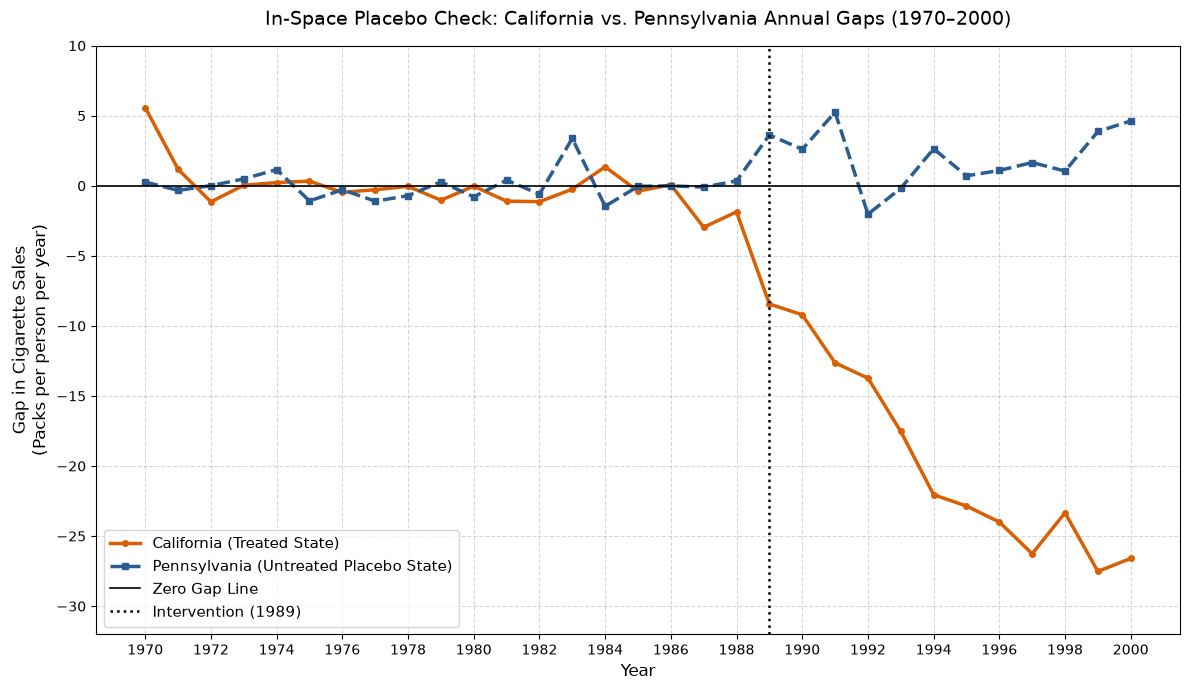

In [13]:
df_raw = pd.read_csv('data.csv')
df = df_raw.copy()

cigsale_wide = df.pivot(index='year', columns='state', values='cigsale')
TREATED = 'California'
PRE_PERIOD, POST_PERIOD, FULL_PERIOD = list(range(1970, 1989)), list(range(1989, 2001)), list(range(1970, 2001))

ca_pre_mean = cigsale_wide.loc[PRE_PERIOD, TREATED].mean()
untreated_pre_means = cigsale_wide.loc[PRE_PERIOD].drop(columns=[TREATED]).mean()
mean_diffs = (untreated_pre_means - ca_pre_mean).abs().sort_values()
PLACEBO = mean_diffs.index[0]

print("=== PLACEBO SELECTION DIAGNOSTIC ===")
print(f"California Pre-Treatment Mean (1970–1988):  {ca_pre_mean:.2f} packs per person")
print(f"Selected Placebo State:                     {PLACEBO}")
print(f"Placebo Pre-Treatment Mean (1970–1988):     {untreated_pre_means[PLACEBO]:.2f} packs per person")
print(f"Absolute Difference:                       {mean_diffs.iloc[0]:.4f} packs per person\n")

def fit_synth(target, donors):
    Y_pre, X_pre = cigsale_wide.loc[PRE_PERIOD, target].values, cigsale_wide.loc[PRE_PERIOD, donors].values
    res = minimize(
        lambda w: (np.mean((X_pre @ w - Y_pre)**2), (2.0 / len(PRE_PERIOD)) * (X_pre.T @ (X_pre @ w - Y_pre))),
        np.ones(len(donors)) / len(donors), jac=True, method='SLSQP',
        bounds=[(0.0, 1.0)] * len(donors), constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        options={'ftol': 1e-12}
    )
    gaps = cigsale_wide.loc[FULL_PERIOD, target] - (cigsale_wide.loc[FULL_PERIOD, donors] @ res.x)
    pre_mspe, post_mspe = np.mean(gaps.loc[PRE_PERIOD] ** 2), np.mean(gaps.loc[POST_PERIOD] ** 2)
    return gaps, np.sqrt(pre_mspe), pre_mspe, post_mspe, post_mspe / pre_mspe

ca_gaps, ca_rmse, ca_pre_m, ca_post_m, ca_ratio = fit_synth(TREATED, [c for c in cigsale_wide.columns if c != TREATED])
pa_gaps, pa_rmse, pa_pre_m, pa_post_m, pa_ratio = fit_synth(PLACEBO, [c for c in cigsale_wide.columns if c not in [TREATED, PLACEBO]])

print("=== TREATED VS. PLACEBO SYNTHETIC CONTROL METRICS ===")
comparison_df = pd.DataFrame({
    'Metric': ['Pre-Treatment RMSE (1970–1988)', 'Pre-Treatment MSPE', 'Post-Treatment MSPE (1989–2000)', 'Post / Pre MSPE Ratio'],
    'California (Treated)': [f"{ca_rmse:.4f}", f"{ca_pre_m:.4f}", f"{ca_post_m:.4f}", f"{ca_ratio:.2f}"],
    f"{PLACEBO} (Placebo)": [f"{pa_rmse:.4f}", f"{pa_pre_m:.4f}", f"{pa_post_m:.4f}", f"{pa_ratio:.2f}"]
})
print(comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(FULL_PERIOD, ca_gaps, color='#d95f02', lw=2.5, marker='o', ms=4, label='California (Treated State)')
ax.plot(FULL_PERIOD, pa_gaps, color='#2b5c8f', lw=2.5, ls='--', marker='s', ms=4, label=f'{PLACEBO} (Untreated Placebo State)')
ax.axhline(0, color='black', lw=1.2, label='Zero Gap Line')
ax.axvline(1989, color='black', ls=':', lw=1.8, label='Intervention (1989)')

ax.set_ylim(-32, 10)
ax.set_title(f'In-Space Placebo Check: California vs. {PLACEBO} Annual Gaps (1970–2000)', fontsize=14, pad=15)
ax.set_xlabel('Year', fontsize=12); ax.set_ylabel('Gap in Cigarette Sales\n(Packs per person per year)', fontsize=12)
ax.set_xticks(range(1970, 2001, 2))
ax.grid(True, ls='--', alpha=0.5); ax.legend(loc='lower left', fontsize=11)
plt.tight_layout(); plt.show()